<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/topics_in_qm/aqm_ch09_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Topics in Quantum Mechanics* — `aqm_ch09_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# AQM Chapter 9 — Figures
**Quantum Foundations**

| Fig | Content |
|-----|---------|
| 9.1 | Bell test setup schematic |
| 9.2 | Correlation $E(\theta)$: QM vs LHV bound |
| 9.3 | CHSH game: classical vs quantum win probability |
| 9.4 | Quantum teleportation circuit diagram |
| 9.5 | Bloch sphere: pure/mixed/maximally mixed states + decoherence |
| 9.6 | Von Neumann entropy $S(\rho)$ vs purity |
| 9.7 | Decoherence: off-diagonal decay + Bloch vector shrinkage |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Circle, FancyArrow
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D
import os, zipfile

BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#ffb347'

plt.rcParams.update({
    'figure.facecolor' : BG,
    'axes.facecolor'   : BG,
    'text.color'       : FG,
    'axes.labelcolor'  : FG,
    'xtick.color'      : FG,
    'ytick.color'      : FG,
    'axes.edgecolor'   : EDGE,
    'grid.color'       : EDGE,
    'grid.alpha'       : 0.30,
    'font.family'      : 'DejaVu Sans',
    'font.size'        : 13,
    'axes.titlesize'   : 14,
    'axes.titleweight' : 'bold',
    'axes.titlecolor'  : BLUE,
    'legend.framealpha': 0.3,
    'legend.edgecolor' : EDGE,
})

OUTDIR = 'figures/ch09'
os.makedirs(OUTDIR, exist_ok=True)

def save(name):
    plt.savefig(f'{OUTDIR}/{name}', dpi=180,
                bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'  saved -> {OUTDIR}/{name}')

print('Setup complete.')

Setup complete.


## Figure 9.1 — Bell Test Setup
**Physics**: entangled pair emitted from source; Alice measures with setting $\hat{a}$ or $\hat{a}'$;
Bob measures with $\hat{b}$ or $\hat{b}'$; correlations $E(\hat{a},\hat{b})$ compared to CHSH bound.

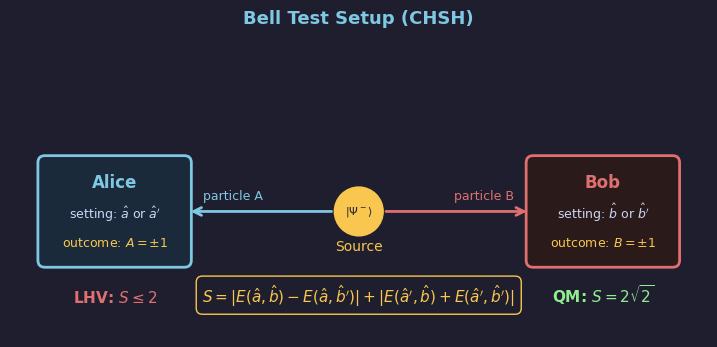

  saved -> figures/ch09/fig01_bell_test_setup.png


In [2]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.set_facecolor(BG)
fig.patch.set_facecolor(BG)
ax.set_xlim(-5, 5)
ax.set_ylim(-1.8, 2.5)
ax.set_aspect('equal')
ax.axis('off')

# Source
src = Circle((0, 0), 0.35, color=YELLOW, zorder=5)
ax.add_patch(src)
ax.text(0, 0, r'$|\Psi^-\rangle$', color=BG, ha='center', va='center',
        fontsize=8, fontweight='bold', zorder=6)
ax.text(0, -0.55, 'Source', color=YELLOW, ha='center', fontsize=10)

# Photon paths
ax.annotate('', xy=(-2.45, 0), xytext=(-0.35, 0),
            arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.0,
                            mutation_scale=14))
ax.annotate('', xy=(2.45, 0), xytext=(0.35, 0),
            arrowprops=dict(arrowstyle='->', color=RED, lw=2.0,
                            mutation_scale=14))
ax.text(-1.8, 0.18, 'particle A', color=BLUE, fontsize=9, ha='center')
ax.text( 1.8, 0.18, 'particle B', color=RED,  fontsize=9, ha='center')

# Alice detector
alice_box = mpatches.FancyBboxPatch((-4.5, -0.7), 2.0, 1.4,
    boxstyle='round,pad=0.1', edgecolor=BLUE, facecolor='#1a2a3a', lw=2)
ax.add_patch(alice_box)
ax.text(-3.5, 0.35, 'Alice', color=BLUE, ha='center', fontsize=12,
        fontweight='bold')
ax.text(-3.5, -0.1, r'setting: $\hat{a}$ or $\hat{a}^\prime$',
        color=FG, ha='center', fontsize=9)
ax.text(-3.5, -0.5, r'outcome: $A = \pm 1$',
        color=YELLOW, ha='center', fontsize=9)

# Bob detector
bob_box = mpatches.FancyBboxPatch((2.5, -0.7), 2.0, 1.4,
    boxstyle='round,pad=0.1', edgecolor=RED, facecolor='#2a1a1a', lw=2)
ax.add_patch(bob_box)
ax.text(3.5, 0.35, 'Bob', color=RED, ha='center', fontsize=12,
        fontweight='bold')
ax.text(3.5, -0.1, r'setting: $\hat{b}$ or $\hat{b}^\prime$',
        color=FG, ha='center', fontsize=9)
ax.text(3.5, -0.5, r'outcome: $B = \pm 1$',
        color=YELLOW, ha='center', fontsize=9)

# CHSH expression
ax.text(0, -1.3,
        r'$S = |E(\hat{a},\hat{b}) - E(\hat{a},\hat{b}^\prime)| + '
        r'|E(\hat{a}^\prime,\hat{b}) + E(\hat{a}^\prime,\hat{b}^\prime)|$',
        color=YELLOW, ha='center', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.4', fc=BG, ec=YELLOW, lw=1.0))

ax.text(-3.5, -1.3, r'LHV: $S \leq 2$',
        color=RED, ha='center', fontsize=11, fontweight='bold')
ax.text( 3.5, -1.3, r'QM: $S = 2\sqrt{2}$',
        color=GREEN, ha='center', fontsize=11, fontweight='bold')

ax.set_title('Bell Test Setup (CHSH)', color=BLUE, fontsize=13, pad=10)
save('fig01_bell_test_setup.png')

## Figure 9.2 — Correlation $E(\theta)$: QM vs LHV
**Physics**: QM predicts $E(\theta) = -\cos\theta$ for singlet.
Best LHV is piecewise linear: $E_{\rm LHV}(\theta) = 1 - 2\theta/\pi$ for $\theta\in[0,\pi]$.
CHSH optimal angles: $0, \pi/4, \pi/2, 3\pi/4$.

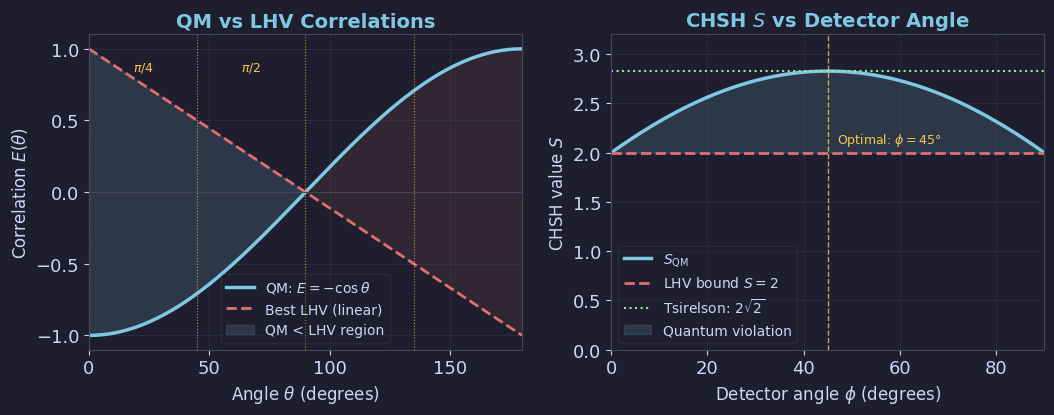

  saved -> figures/ch09/fig02_bell_violation.png


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.patch.set_facecolor(BG)

theta = np.linspace(0, np.pi, 500)
theta_deg = np.degrees(theta)

E_QM  = -np.cos(theta)
# Best deterministic LHV: piecewise linear
E_LHV = 1 - 2 * theta / np.pi

# ── Left: E(θ) comparison ─────────────────────────────────────
ax1.plot(theta_deg, E_QM,  color=BLUE,   lw=2.5, label=r'QM: $E=-\cos\theta$')
ax1.plot(theta_deg, E_LHV, color=RED,    lw=2.0, ls='--',
         label='Best LHV (linear)')
ax1.fill_between(theta_deg, E_LHV, E_QM,
                 where=E_QM < E_LHV, color=BLUE, alpha=0.15,
                 label='QM < LHV region')
ax1.fill_between(theta_deg, E_LHV, E_QM,
                 where=E_QM > E_LHV, color=RED, alpha=0.10)

# Mark optimal CHSH angles
opt_angles = [0, 45, 90, 135]
for ang in opt_angles:
    ax1.axvline(ang, color=YELLOW, lw=0.8, ls=':', alpha=0.7)
ax1.text(22.5, 0.85, r'$\pi/4$', color=YELLOW, ha='center', fontsize=9)
ax1.text(67.5, 0.85, r'$\pi/2$', color=YELLOW, ha='center', fontsize=9)

ax1.set_xlabel(r'Angle $\theta$ (degrees)', fontsize=12)
ax1.set_ylabel(r'Correlation $E(\theta)$', fontsize=12)
ax1.set_title(r'QM vs LHV Correlations', color=BLUE)
ax1.legend(fontsize=10, labelcolor=FG)
ax1.set_xlim(0, 180)
ax1.set_ylim(-1.1, 1.1)
ax1.axhline(0, color=EDGE, lw=0.7)
ax1.grid(True)

# ── Right: CHSH S value as function of angle between axes ─────
# With optimal arrangement a=0, a'=π/2, b=π/4, b'=-π/4
# S(φ) = 2|cos φ + cos φ| style demonstration
phi = np.linspace(0, np.pi/2, 300)
# CHSH S for settings 0, phi, phi/2, -phi/2 (parametrised by detector angle)
S_QM  = 2 * np.sqrt(2) * np.abs(np.cos(phi - np.pi/4))
S_LHV = 2 * np.ones_like(phi)

ax2.plot(np.degrees(phi), S_QM,  color=BLUE,  lw=2.5, label=r'$S_{\rm QM}$')
ax2.axhline(2,            color=RED,   lw=2.0, ls='--', label=r'LHV bound $S=2$')
ax2.axhline(2*np.sqrt(2), color=GREEN, lw=1.5, ls=':',
            label=r'Tsirelson: $2\sqrt{2}$')
ax2.fill_between(np.degrees(phi), 2, S_QM, where=S_QM > 2,
                 color=BLUE, alpha=0.15, label='Quantum violation')

# Optimal angle marker
ax2.axvline(45, color=YELLOW, lw=1.0, ls='--', alpha=0.8)
ax2.text(47, 2.1, r'Optimal: $\phi=45°$', color=YELLOW, fontsize=9)

ax2.set_xlabel(r'Detector angle $\phi$ (degrees)', fontsize=12)
ax2.set_ylabel(r'CHSH value $S$', fontsize=12)
ax2.set_title(r'CHSH $S$ vs Detector Angle', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG)
ax2.set_xlim(0, 90)
ax2.set_ylim(0, 3.2)
ax2.grid(True)

plt.tight_layout(pad=1.5)
save('fig02_bell_violation.png')

## Figure 9.3 — CHSH Game: Classical vs Quantum
**Physics**: classical best strategy wins 75%; quantum strategy with shared Bell pair wins $\cos^2(\pi/8) \approx 85.4\%$.

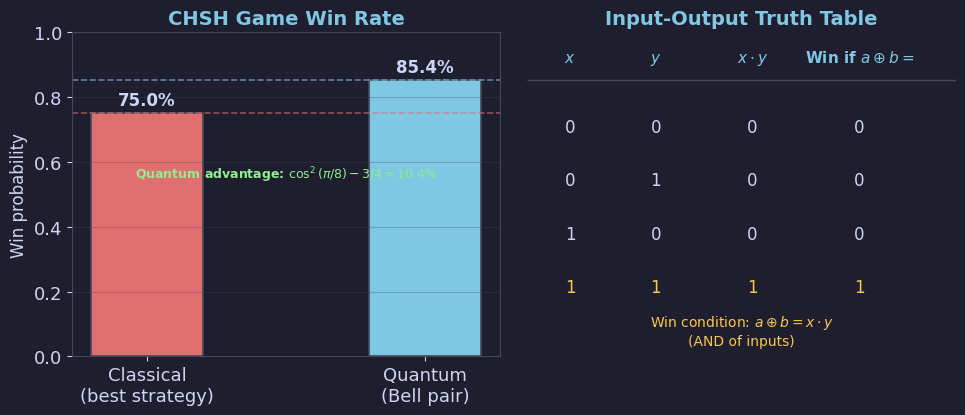

  saved -> figures/ch09/fig03_CHSH_game.png


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))
fig.patch.set_facecolor(BG)

# ── Left: bar chart comparison ────────────────────────────────
labels  = ['Classical\n(best strategy)', 'Quantum\n(Bell pair)']
values  = [0.75, np.cos(np.pi/8)**2]
colors  = [RED, BLUE]

bars = ax1.bar(labels, values, color=colors, width=0.4,
               edgecolor=EDGE, linewidth=1.2)
ax1.axhline(0.75, color=RED,   lw=1.2, ls='--', alpha=0.6)
ax1.axhline(values[1], color=BLUE, lw=1.2, ls='--', alpha=0.6)

for bar, val in zip(bars, values):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.012,
             f'{val:.1%}', ha='center', va='bottom',
             color=FG, fontsize=12, fontweight='bold')

ax1.set_ylim(0, 1.0)
ax1.set_ylabel('Win probability', fontsize=12)
ax1.set_title('CHSH Game Win Rate', color=BLUE)
ax1.grid(True, axis='y')
ax1.text(0.5, 0.55,
         r'Quantum advantage: $\cos^2(\pi/8) - 3/4 \approx 10.4\%$',
         color=GREEN, ha='center', fontsize=9, weight='bold',
         transform=ax1.transAxes)

# ── Right: input-output truth table ───────────────────────────
ax2.set_facecolor(BG)
ax2.set_xlim(0, 4)
ax2.set_ylim(-0.5, 5)
ax2.axis('off')

# Table header
headers = ['$x$', '$y$', '$x\\cdot y$', 'Win if $a\\oplus b=$']
xs = [0.4, 1.2, 2.1, 3.1]
for x, h in zip(xs, headers):
    ax2.text(x, 4.5, h, color=BLUE, ha='center', fontsize=11,
             fontweight='bold')
ax2.hlines(4.2, 0, 4, colors=EDGE, lw=1)

rows = [(0, 0, 0, 0), (0, 1, 0, 0), (1, 0, 0, 0), (1, 1, 1, 1)]
row_colors = [FG, FG, FG, YELLOW]
for i, (x, y, xy, win) in enumerate(rows):
    y_pos = 3.3 - i * 0.9
    for xpos, val in zip(xs, [x, y, xy, win]):
        ax2.text(xpos, y_pos, str(val), color=row_colors[i],
                 ha='center', fontsize=12)

ax2.text(2.0, -0.3,
         'Win condition: $a \\oplus b = x \\cdot y$\n(AND of inputs)',
         color=YELLOW, ha='center', fontsize=10)
ax2.set_title('Input-Output Truth Table', color=BLUE)

plt.tight_layout(pad=1.5)
save('fig03_CHSH_game.png')

## Figure 9.4 — Quantum Teleportation Circuit
**Physics**: 3-qubit circuit; qubit 1 = unknown state, qubits 2+3 = Bell pair;
Alice performs Bell measurement on 1+2; sends 2 classical bits; Bob corrects qubit 3.

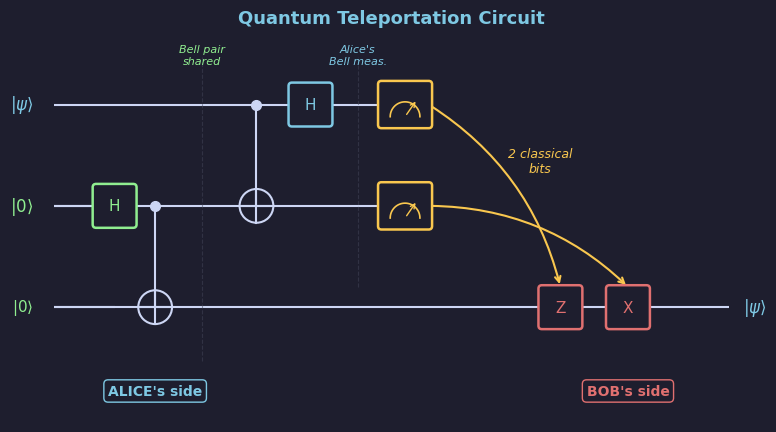

  saved -> figures/ch09/fig04_teleportation_circuit.png


In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_facecolor(BG)
fig.patch.set_facecolor(BG)
ax.set_xlim(-0.5, 10.5)
ax.set_ylim(-1.2, 4.5)
ax.set_aspect('equal')
ax.axis('off')

def wire(ax, y, x0, x1, color=FG, lw=1.5):
    ax.hlines(y, x0, x1, colors=color, lw=lw)

def gate(ax, x, y, label, color=BLUE, w=0.55, h=0.55, fs=11):
    box = mpatches.FancyBboxPatch((x-w/2, y-h/2), w, h,
        boxstyle='round,pad=0.05', edgecolor=color,
        facecolor=BG, lw=1.8, zorder=4)
    ax.add_patch(box)
    ax.text(x, y, label, color=color, ha='center', va='center',
            fontsize=fs, zorder=5)

def cnot(ax, x, ctrl, tgt):
    ax.vlines(x, min(ctrl,tgt), max(ctrl,tgt), colors=FG, lw=1.5, zorder=3)
    ax.plot(x, ctrl, 'o', color=FG, ms=7, zorder=5)
    circ = Circle((x, tgt), 0.25, fill=False, edgecolor=FG, lw=1.5, zorder=4)
    ax.add_patch(circ)
    ax.plot([x-0.25, x+0.25], [tgt, tgt], color=FG, lw=1.5, zorder=5)
    ax.plot([x, x], [tgt-0.25, tgt+0.25], color=FG, lw=1.5, zorder=5)

def measure(ax, x, y, color=YELLOW):
    box = mpatches.FancyBboxPatch((x-0.35, y-0.30), 0.70, 0.60,
        boxstyle='round,pad=0.05', edgecolor=color,
        facecolor=BG, lw=1.8, zorder=4)
    ax.add_patch(box)
    # Meter arc
    arc_t = np.linspace(0, np.pi, 50)
    ax.plot(x + 0.22*np.cos(arc_t), y - 0.18 + 0.22*np.sin(arc_t),
            color=color, lw=1.2, zorder=5)
    ax.annotate('', xy=(x+0.18, y+0.08), xytext=(x, y-0.18),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=1.0, mutation_scale=8), zorder=5)

# Wire y-positions
y1, y2, y3 = 3.5, 2.0, 0.5

# Wires
wire(ax, y1, 0, 5.5)
wire(ax, y2, 0, 5.5)
#wire(ax, y3, 1.5, 10.0)
wire(ax, y3, 0, 5.5)

# State labels
ax.text(-0.3, y1, r'$|\psi\rangle$', color=BLUE, ha='right', va='center',
        fontsize=12)
ax.text(-0.3, y2, r'$|0\rangle$', color=GREEN, ha='right', va='center',
        fontsize=12)
ax.text(-0.3, y3, r'$|0\rangle$', color=GREEN, ha='right', va='center',
        fontsize=11)

# Bell pair preparation (H + CNOT on qubits 2,3)
gate(ax, 0.9, y2, 'H', color=GREEN)
wire(ax, y2, 0, 0.9)
wire(ax, y3, 0, 0.9)
cnot(ax, 1.5, y2, y3)

# Vertical separator: Bell pair prepared
ax.vlines(2.2, -0.3, 4.2, colors=EDGE, lw=0.8, ls='--', alpha=0.5)
ax.text(2.2, 4.1, 'Bell pair\nshared', color=GREEN, ha='center',
        fontsize=8, style='italic')

# Alice's Bell measurement: CNOT then H on qubit 1
cnot(ax, 3.0, y1, y2)
gate(ax, 3.8, y1, 'H', color=BLUE)

# Alice separator
ax.vlines(4.5, 0.8, 4.2, colors=EDGE, lw=0.8, ls='--', alpha=0.5)
ax.text(4.5, 4.1, "Alice's\nBell meas.", color=BLUE, ha='center',
        fontsize=8, style='italic')

# Measurements
measure(ax, 5.2, y1, color=YELLOW)
measure(ax, 5.2, y2, color=YELLOW)

# Classical communication (double lines)
for y_src, y_tgt, x_gate in [(y1, y3, 7.5), (y2, y3, 8.5)]:
    ax.annotate('', xy=(x_gate, y_tgt + 0.3),
                xytext=(5.55, y_src),
                arrowprops=dict(arrowstyle='->', color=YELLOW,
                                lw=1.5, mutation_scale=10,
                                connectionstyle='arc3,rad=-0.2'))

# Classical comm label
ax.text(7.2, 2.5, '2 classical\nbits', color=YELLOW, ha='center',
        fontsize=9, style='italic')

# Bob's corrections (Z then X gates)
wire(ax, y3, 5.5, 10.0)
gate(ax, 7.5, y3, 'Z', color=RED)
gate(ax, 8.5, y3, 'X', color=RED)

# Output
ax.text(10.2, y3, r'$|\psi\rangle$', color=BLUE, ha='left', va='center',
        fontsize=12)

# Region labels
ax.text(1.5, -0.8, "ALICE's side", color=BLUE, ha='center', fontsize=10,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=BLUE, lw=1))
ax.text(8.5, -0.8, "BOB's side", color=RED, ha='center', fontsize=10,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=RED, lw=1))

ax.set_title('Quantum Teleportation Circuit', color=BLUE, fontsize=13, pad=10)
save('fig04_teleportation_circuit.png')

## Figure 9.5 — Bloch Sphere: Pure, Mixed, Decoherence
**Physics**: pure states on surface ($|\mathbf{r}|=1$); mixed states inside ($|\mathbf{r}|<1$);
maximally mixed at centre ($\mathbf{r}=0$); decoherence = Bloch vector shrinks toward $z$-axis then to centre.

  saved → figures/ch09/fig05_bloch_mixed.png  (941×455px)


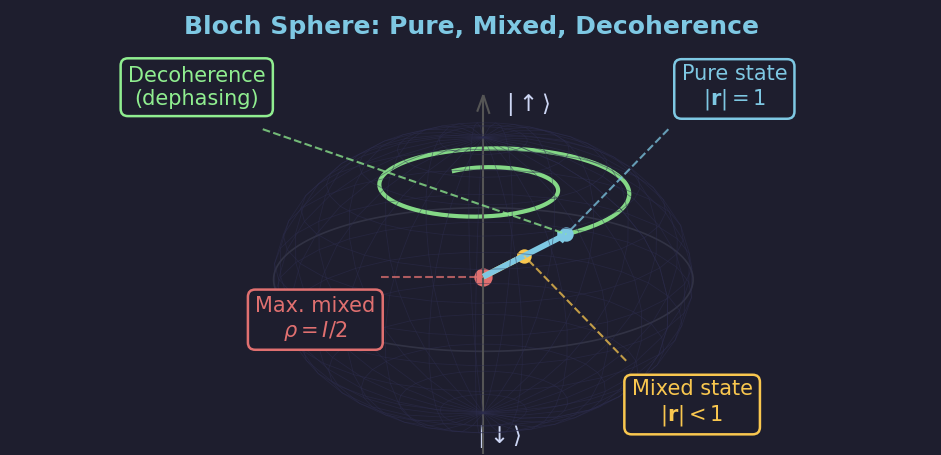

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D, proj3d
import matplotlib.lines as mlines
from PIL import Image
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'; RED='#e07070'
BG_RGB = np.array([30, 30, 46])

fig = plt.figure(figsize=(8, 7))
ax = fig.add_axes([0.12, 0.04, 0.76, 0.92], projection='3d')
ax.set_facecolor(BG); fig.patch.set_facecolor(BG)

u = np.linspace(0, 2*np.pi, 30); v = np.linspace(0, np.pi, 16)
ax.plot_wireframe(np.outer(np.cos(u),np.sin(v)),
                  np.outer(np.sin(u),np.sin(v)),
                  np.outer(np.ones(30),np.cos(v)),
                  color='#2d2d4e', lw=0.4, alpha=0.5)
eq = np.linspace(0, 2*np.pi, 150)
ax.plot(np.cos(eq), np.sin(eq), 0, color=EDGE, lw=0.8, alpha=0.5)
ax.quiver(0,0,-1.3, 0,0,2.6, color='#555', lw=1.0, arrow_length_ratio=0.05)

theta_p, phi_p = np.radians(50), np.radians(-30)
r_pure  = np.array([np.sin(theta_p)*np.cos(phi_p),
                    np.sin(theta_p)*np.sin(phi_p),
                    np.cos(theta_p)])
r_mixed = r_pure * 0.50

ax.quiver(0,0,0,*r_pure,  color=BLUE,   lw=2.8, arrow_length_ratio=0.09)
ax.quiver(0,0,0,*r_mixed, color=YELLOW, lw=2.8, arrow_length_ratio=0.14)
ax.scatter([0],[0],[0], color=RED,    s=60, zorder=6)
ax.scatter(*r_pure,    color=BLUE,   s=35, zorder=7)
ax.scatter(*r_mixed,   color=YELLOW, s=35, zorder=7)

t_dec = np.linspace(0, 3*np.pi, 300)
decay = np.exp(-t_dec/(3*np.pi))
dec_x = decay*np.sin(theta_p)*np.cos(phi_p+t_dec)
dec_y = decay*np.sin(theta_p)*np.sin(phi_p+t_dec)
dec_z = np.cos(theta_p)*np.ones_like(t_dec)
ax.plot(dec_x, dec_y, dec_z, color=GREEN, lw=2.0, alpha=0.9)
spiral_pt = np.array([dec_x[0], dec_y[0], dec_z[0]])

ax.text( 0.08,  0.08,  1.18, r'$|\uparrow\rangle$',  color=FG, fontsize=11)
ax.text(-0.08,  0.08, -1.28, r'$|\downarrow\rangle$', color=FG, fontsize=11)

ax.set_xlim(-1.4,1.4); ax.set_ylim(-1.4,1.4); ax.set_zlim(-1.5,1.5)
ax.set_axis_off()
ax.view_init(elev=20, azim=-60)
ax.set_title('Bloch Sphere: Pure, Mixed, Decoherence', color=BLUE, fontsize=12, pad=8)

fig.canvas.draw()

def to_fig(ax, fig, pt3d):
    x2, y2, _ = proj3d.proj_transform(*pt3d, ax.get_proj())
    xd, yd = ax.transData.transform((x2, y2))
    return fig.transFigure.inverted().transform((xd, yd))

pp = to_fig(ax, fig, r_pure)
mp = to_fig(ax, fig, r_mixed)
cp = to_fig(ax, fig, [0,0,0])
sp = to_fig(ax, fig, spiral_pt)

def annotate(fig, target, dx, dy, text, color):
    tx, ty = target
    lx, ly = tx+dx, ty+dy
    fig.text(lx, ly, text, color=color, fontsize=10, ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.35', fc='#1e1e2e', ec=color, lw=1.2))
    bx = lx - np.sign(dx)*0.055
    by = ly - np.sign(dy)*0.040
    fig.add_artist(mlines.Line2D([bx,tx],[by,ty],
        transform=fig.transFigure, color=color, lw=1.0, ls='--', alpha=0.75))

D = 0.14
annotate(fig, pp,  +D,      +D,   'Pure state\n$|\\mathbf{r}|=1$',  BLUE)
annotate(fig, mp,  +D,      -D,   'Mixed state\n$|\\mathbf{r}|<1$', YELLOW)
annotate(fig, cp,  -D,   -0.04,   'Max. mixed\n$\\rho=I/2$',        RED)
annotate(fig, sp,  -D*2.2,  +D,   'Decoherence\n(dephasing)',        GREEN)

# ── 1. savefig로 저장 ─────────────────────────────────────────────
path = f'{OUTDIR}/fig05_bloch_mixed.png'
plt.savefig(path, dpi=150, bbox_inches='tight', facecolor=BG)
plt.close(fig)
#plt.show()

# ── 2. PIL로 불러들여 빈 공간 제거 후 같은 경로에 덮어쓰기 ────────
img = Image.open(path).convert('RGB')
arr = np.array(img)
row_density = (np.abs(arr.astype(int) - BG_RGB).max(axis=2) > 8).sum(axis=1)

title_end    = max((r for r in range(min(80, len(row_density))) if row_density[r] > 5), default=30)
sphere_start = next((r for r in range(title_end+1, len(row_density)) if row_density[r] > 5), title_end+1)

PAD = 10
title_part  = img.crop((0, 0,                  img.width, title_end + PAD))
sphere_part = img.crop((0, sphere_start - PAD, img.width, img.height))

arr2 = np.array(sphere_part)
row_density2 = (np.abs(arr2.astype(int) - BG_RGB).max(axis=2) > 8).sum(axis=1)
bottom = max((r for r in range(len(row_density2)) if row_density2[r] > 5), default=len(row_density2)-1)
sphere_part = sphere_part.crop((0, 0, sphere_part.width, bottom + PAD))

result = Image.new('RGB', (img.width, title_part.height + sphere_part.height), (30,30,46))
result.paste(title_part,  (0, 0))
result.paste(sphere_part, (0, title_part.height))

result.save(path, dpi=(150,150))   # 같은 경로에 덮어쓰기
print(f'  saved → {path}  ({result.size[0]}×{result.size[1]}px)')

img = Image.open(path)
display(img)

## Figure 9.6 — Von Neumann Entropy
**Physics**: $S(\rho) = -\mathrm{tr}(\rho\ln\rho)$. For a qubit with eigenvalues $\lambda, 1-\lambda$:
$S = -\lambda\ln\lambda - (1-\lambda)\ln(1-\lambda)$ (binary entropy). Maximum $S=\ln 2$ at $\lambda=1/2$.

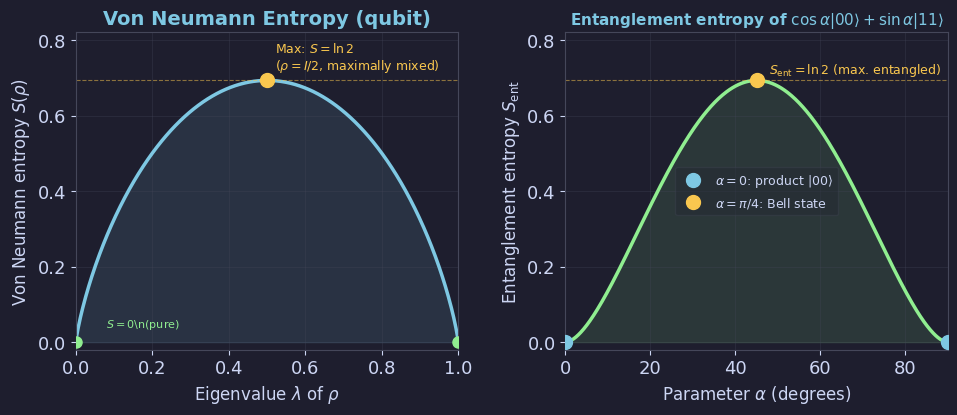

  saved -> figures/ch09/fig06_von_neumann_entropy.png


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))
fig.patch.set_facecolor(BG)

# ── Left: binary entropy H(λ) ────────────────────────────────
lam = np.linspace(1e-9, 1-1e-9, 500)
S_bin = -lam*np.log(lam) - (1-lam)*np.log(1-lam)

ax1.plot(lam, S_bin, color=BLUE, lw=2.5)
ax1.fill_between(lam, 0, S_bin, color=BLUE, alpha=0.12)

# Annotations
ax1.plot(0.5, np.log(2), 'o', color=YELLOW, ms=10, zorder=5)
ax1.text(0.52, np.log(2)+0.03,
         r'Max: $S=\ln 2$' + '\n' + r'($\rho = I/2$, maximally mixed)',
         color=YELLOW, fontsize=9)
ax1.plot(0, 0, 'o', color=GREEN, ms=8, zorder=5)
ax1.plot(1, 0, 'o', color=GREEN, ms=8, zorder=5)
ax1.text(0.08, 0.04, r'$S=0$\n(pure)', color=GREEN, fontsize=8)

ax1.set_xlabel(r'Eigenvalue $\lambda$ of $\rho$', fontsize=12)
ax1.set_ylabel(r'Von Neumann entropy $S(\rho)$', fontsize=12)
ax1.set_title('Von Neumann Entropy (qubit)', color=BLUE)
ax1.set_xlim(0, 1)
ax1.set_ylim(-0.02, 0.82)
ax1.axhline(np.log(2), color=YELLOW, lw=0.8, ls='--', alpha=0.5)
ax1.grid(True)

# ── Right: entanglement entropy for 2-qubit pure state ────────
# |ψ⟩ = cos(α)|00⟩ + sin(α)|11⟩; ρ_A eigenvalues: cos²α, sin²α
alpha = np.linspace(0, np.pi/2, 500)
lam1 = np.cos(alpha)**2
lam2 = np.sin(alpha)**2
eps = 1e-12
S_ent = -(lam1+eps)*np.log(lam1+eps) - (lam2+eps)*np.log(lam2+eps)

ax2.plot(np.degrees(alpha), S_ent, color=GREEN, lw=2.5)
ax2.fill_between(np.degrees(alpha), 0, S_ent, color=GREEN, alpha=0.12)

# Special points
ax2.plot(0,  0,       'o', color=BLUE, ms=10, zorder=5,
         label=r'$\alpha=0$: product $|00\rangle$')
ax2.plot(45, np.log(2), 'o', color=YELLOW, ms=10, zorder=5,
         label=r'$\alpha=\pi/4$: Bell state')
ax2.plot(90, 0, 'o', color=BLUE, ms=10, zorder=5)

ax2.axhline(np.log(2), color=YELLOW, lw=0.8, ls='--', alpha=0.5)
ax2.text(48, np.log(2)+0.02,
         r'$S_{\rm ent}=\ln 2$ (max. entangled)',
         color=YELLOW, fontsize=9)

ax2.set_xlabel(r'Parameter $\alpha$ (degrees)', fontsize=12)
ax2.set_ylabel(r'Entanglement entropy $S_{\rm ent}$', fontsize=12)
ax2.set_title(
    r'Entanglement entropy of $\cos\alpha|00\rangle+\sin\alpha|11\rangle$',
    color=BLUE, fontsize=11)
ax2.set_xlim(0, 90)
ax2.set_ylim(-0.02, 0.82)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True)

plt.tight_layout(pad=1.5)
save('fig06_von_neumann_entropy.png')

## Figure 9.7 — Decoherence: Coherence Decay and Lindblad
**Physics**: pure dephasing → off-diagonal $|\rho_{01}(t)| = |\rho_{01}(0)|e^{-\Gamma t}$;
amplitude damping → both coherences and populations change.

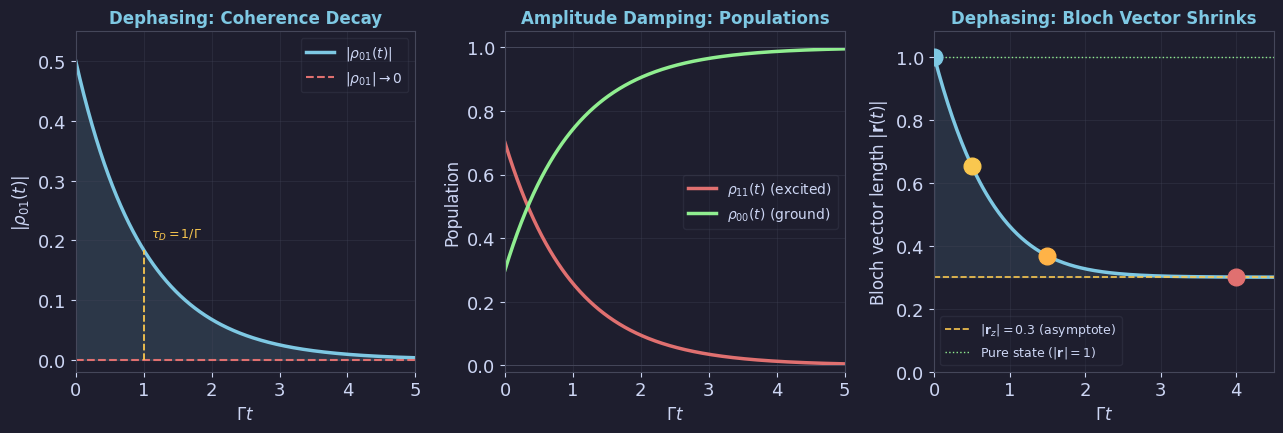

  saved -> figures/ch09/fig07_decoherence.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
fig.patch.set_facecolor(BG)

t = np.linspace(0, 5, 500)  # time in units of 1/Γ
Gamma = 1.0

# ── Panel 1: coherence decay (dephasing) ──────────────────────
ax = axes[0]
rho01_0 = 0.5  # initial coherence
rho01_t = rho01_0 * np.exp(-Gamma * t)

ax.plot(t, rho01_t, color=BLUE, lw=2.5, label=r'$|\rho_{01}(t)|$')
ax.plot(t, np.zeros_like(t), color=RED, lw=1.5, ls='--',
        label=r'$|\rho_{01}|\to 0$')
ax.fill_between(t, 0, rho01_t, color=BLUE, alpha=0.15)

tau = 1.0/Gamma
ax.vlines(tau, 0, rho01_0*np.exp(-1), colors=YELLOW, lw=1.3, ls='--')
ax.text(tau+0.1, rho01_0*np.exp(-1)+0.02,
        r'$\tau_D=1/\Gamma$', color=YELLOW, fontsize=9)

ax.set_xlabel(r'$\Gamma t$', fontsize=12)
ax.set_ylabel(r'$|\rho_{01}(t)|$', fontsize=12)
ax.set_title('Dephasing: Coherence Decay', color=BLUE, fontsize=12)
ax.set_xlim(0, 5)
ax.set_ylim(-0.02, 0.55)
ax.legend(fontsize=10, labelcolor=FG)
ax.grid(True)

# ── Panel 2: amplitude damping (populations) ──────────────────
ax2 = axes[1]
# Excited state: ρ₁₁(t) = ρ₁₁(0) e^{-Γt}
# Ground state:  ρ₀₀(t) = 1 - ρ₁₁(t)
rho11_0 = 0.7
rho11_t = rho11_0 * np.exp(-Gamma * t)
rho00_t = 1 - rho11_t

ax2.plot(t, rho11_t, color=RED,   lw=2.5, label=r'$\rho_{11}(t)$ (excited)')
ax2.plot(t, rho00_t, color=GREEN, lw=2.5, label=r'$\rho_{00}(t)$ (ground)')
ax2.axhline(0, color=EDGE, lw=0.7)
ax2.axhline(1, color=EDGE, lw=0.7)

ax2.set_xlabel(r'$\Gamma t$', fontsize=12)
ax2.set_ylabel('Population', fontsize=12)
ax2.set_title('Amplitude Damping: Populations', color=BLUE, fontsize=12)
ax2.set_xlim(0, 5)
ax2.set_ylim(-0.02, 1.05)
ax2.legend(fontsize=10, labelcolor=FG)
ax2.grid(True)

# ── Panel 3: density matrix elements as heatmap (t=0 vs t=2) ──
ax3 = axes[2]
t_vals = [0, 0.5, 1.5, 4.0]
colors_t = [BLUE, YELLOW, ORANGE, RED]
labels_t = [r'$t=0$', r'$\Gamma t=0.5$', r'$\Gamma t=1.5$', r'$\Gamma t=4$']

# Bloch vector magnitude |r(t)| = sqrt(r_z² + r_perp²e^{-2Γt})
# For dephasing: r_z fixed, r_perp decays
r_z    = 0.3   # initial z-component (population difference)
r_perp = np.sqrt(1 - r_z**2)  # initial transverse (pure state)

for ti, color, label in zip(t_vals, colors_t, labels_t):
    r_perp_t = r_perp * np.exp(-Gamma * ti)
    r_mag = np.sqrt(r_z**2 + r_perp_t**2)
    ax3.plot(ti, r_mag, 'o', color=color, ms=12, zorder=5)

t_cont = np.linspace(0, 4.5, 300)
r_perp_cont = r_perp * np.exp(-Gamma * t_cont)
r_mag_cont = np.sqrt(r_z**2 + r_perp_cont**2)
ax3.plot(t_cont, r_mag_cont, color=BLUE, lw=2.5)
ax3.fill_between(t_cont, r_z, r_mag_cont, color=BLUE, alpha=0.12)
ax3.axhline(r_z, color=YELLOW, lw=1.2, ls='--',
            label=fr'$|\mathbf{{r}}_z| = {r_z}$ (asymptote)')
ax3.axhline(1.0, color=GREEN,  lw=1.0, ls=':', label='Pure state ($|\\mathbf{r}|=1$)')

ax3.set_xlabel(r'$\Gamma t$', fontsize=12)
ax3.set_ylabel(r'Bloch vector length $|\mathbf{r}(t)|$', fontsize=12)
ax3.set_title('Dephasing: Bloch Vector Shrinks', color=BLUE, fontsize=12)
ax3.set_xlim(0, 4.5)
ax3.set_ylim(0, 1.08)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True)

plt.tight_layout(pad=1.0)
save('fig07_decoherence.png')

## Auto-zip and Download

In [9]:
from google.colab import files

zip_name = 'aqm_ch09_figures.zip'
fig_dir  = 'figures/ch09'

with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(fig_dir)):
        if fname.endswith('.png'):
            fpath = os.path.join(fig_dir, fname)
            zf.write(fpath, arcname=os.path.join('figures', 'ch09', fname))
            print(f'  added: {fname}')

print(f'\nCreated: {zip_name}  ({os.path.getsize(zip_name)/1024:.0f} KB)')
files.download(zip_name)

  added: fig01_bell_test_setup.png
  added: fig02_bell_violation.png
  added: fig03_CHSH_game.png
  added: fig04_teleportation_circuit.png
  added: fig05_bloch_mixed.png
  added: fig06_von_neumann_entropy.png
  added: fig07_decoherence.png

Created: aqm_ch09_figures.zip  (700 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Figure–Slide Mapping

| File | Slide section | Width |
|------|--------------|-------|
| `fig01_bell_test_setup.png` | 9.1 Bell's Inequality | 90% |
| `fig02_bell_violation.png` | 9.1 Quantum Violation | 95% |
| `fig03_CHSH_game.png` | 9.2 CHSH Game | 92% |
| `fig04_teleportation_circuit.png` | 9.2 Quantum Teleportation | 95% |
| `fig05_bloch_mixed.png` | 9.3 Bloch Sphere for Mixed States | 75% |
| `fig06_von_neumann_entropy.png` | 9.3 Von Neumann Entropy | 95% |
| `fig07_decoherence.png` | 9.5 Decoherence | 97% |